# Naive Bayes
Classifier based on Bayes' theorem + "naive" assumption that features are conditionally independent given the class.
  P(class | x1..xn)  is proportional to  P(class) * Product_i P(xi | class)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.naive_bayes import GaussianNB, MultinomialNB  
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

GaussianNB : For continuous numbers (assumes bell curve)

MultinomialNB : For word counts (text/spam detection)

CountVectorizer : Converts sentences → word count matrix

ConfusionMatrixDisplay : Visual grid showing right vs wrong predictions

## 1. Bayes theorem by hand (tiny example)
P(Disease)=1%, test sensitivity P(+|D)=95%, false-positive rate P(+|not D)=5%.

In [2]:
p_d, p_pos_d, p_pos_nd = 0.01, 0.95, 0.05
p_pos = p_pos_d * p_d + p_pos_nd * (1 - p_d)
print("P(Disease | +ve test) =", round(p_pos_d * p_d / p_pos, 4), " <- posterior is only ~16% because the prior is tiny")

P(Disease | +ve test) = 0.161  <- posterior is only ~16% because the prior is tiny


p_pos = p_pos_d * p_d + p_pos_nd * (1 - p_d)

What this calculates — P(test is positive at all):
Two ways you can get a positive test:
  1. You HAVE disease AND test catches it:   0.95 × 0.01 = 0.0095
  2. You DON'T have disease but false alarm: 0.05 × 0.99 = 0.0495

Total P(positive) = 0.0095 + 0.0495 = 0.059

“Even with a 95% accurate test, if only 1% of people have the disease, a positive result only means 16% chance you’re sick. The tiny prior (1%) drags the posterior down. This surprises most people — it’s why Bayes is important.”

## 2. Gaussian Naive Bayes from scratch (continuous features, Iris)

In [3]:
X, y = load_iris(return_X_y=True)
names = load_iris().target_names
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=1)

class MyGaussianNB:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.prior = np.array([(y == c).mean() for c in self.classes])
        self.mean = np.array([X[y == c].mean(axis=0) for c in self.classes])
        self.var = np.array([X[y == c].var(axis=0) + 1e-9 for c in self.classes])
        return self

    def _log_posterior(self, x):
        # log P(c) + sum_i log N(x_i | mean_ci, var_ci)   (logs avoid numerical underflow)
        log_lik = -0.5 * (np.log(2 * np.pi * self.var) + (x - self.mean) ** 2 / self.var).sum(axis=1)
        return np.log(self.prior) + log_lik

    def predict(self, X):
        return self.classes[[np.argmax(self._log_posterior(x)) for x in X]]

mine = MyGaussianNB().fit(X_train, y_train)
sk = GaussianNB().fit(X_train, y_train)
print("From scratch accuracy:", round(accuracy_score(y_test, mine.predict(X_test)), 4))
print("sklearn accuracy     :", round(accuracy_score(y_test, sk.predict(X_test)), 4))
print("Learned class priors :", mine.prior.round(3))
print("Class means:\n", mine.mean.round(2))

From scratch accuracy: 0.9778
sklearn accuracy     : 0.9778
Learned class priors : [0.333 0.333 0.333]
Class means:
 [[5.02 3.43 1.46 0.24]
 [5.87 2.78 4.27 1.32]
 [6.68 2.99 5.64 2.03]]


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



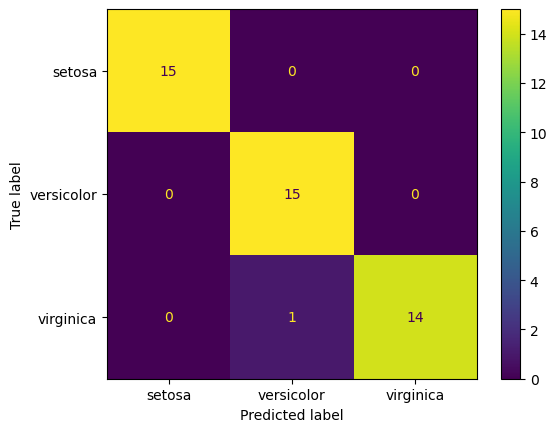

Posterior probabilities for first test flower: [[0. 0. 1.]]


In [4]:
y_pred = sk.predict(X_test)
print(classification_report(y_test, y_pred, target_names=names))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=names)
plt.show()
print("Posterior probabilities for first test flower:", sk.predict_proba(X_test[:1]).round(3))

## 3. Multinomial Naive Bayes for text (spam detection) with Laplace smoothing

In [5]:
texts = ["win free money now", "free lottery winner claim prize", "limited offer win cash", "urgent claim your free reward",
         "cheap loans approved instantly", "meeting at 10 tomorrow", "please review the project report",
         "lunch with the team today", "assignment submission deadline tomorrow", "can we reschedule the class",
         "notes for the ML lecture attached", "project meeting agenda attached"]
labels = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0])  # 1 = spam, 0 = ham

vec = CountVectorizer()
Xt = vec.fit_transform(texts)
for alpha in [1.0, 0.0001]:   # alpha=1 -> Laplace smoothing
    nb = MultinomialNB(alpha=alpha).fit(Xt, labels)
    msg = ["claim your free prize now", "project report meeting tomorrow", "free meeting"]
    probs = nb.predict_proba(vec.transform(msg))[:, 1]
    print(f"alpha={alpha}:", {m: round(float(p), 3) for m, p in zip(msg, probs)})

alpha=1.0: {'claim your free prize now': 0.993, 'project report meeting tomorrow': 0.024, 'free meeting': 0.565}
alpha=0.0001: {'claim your free prize now': 1.0, 'project report meeting tomorrow': 0.0, 'free meeting': 0.707}


## 4. Why smoothing is needed: a word never seen in spam would give P=0 and kill the whole product

In [6]:
nb = MultinomialNB(alpha=1).fit(Xt, labels)
top = np.argsort(nb.feature_log_prob_[1] - nb.feature_log_prob_[0])[-5:]
print("Words most indicative of spam:", vec.get_feature_names_out()[top])

Words most indicative of spam: ['limited' 'cheap' 'win' 'claim' 'free']


Full Mental Model
Naive Bayes in 4 steps:
─────────────────────────────────────────────────────
TRAINING:
  1. Count how often each class appears → Prior
  2. For each class, learn what each feature looks like
     → Gaussian: learn mean + variance
     → Multinomial: learn word frequencies

PREDICTION:
  3. For new data point, calculate:
     score(class) = log(prior) + sum of log(likelihoods)
  4. Pick class with highest score

WHY IT'S "NAIVE":
  It assumes features are INDEPENDENT given the class.
  "free" and "win" treated as unrelated — even if
  they often appear together in spam.
  Wrong assumption, but works surprisingly well!
─────────────────────────────────────────────────────

GaussianNB   → continuous numbers → bell curve assumption
MultinomialNB → word counts → good for text/spam
BernoulliNB  → binary features → word present/absent